In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("/kaggle/input/datasets/mahmodradwan/titanic/titanic_clean.csv")

X = df.drop(columns="target").values
y = df["target"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=50, max_depth=5,
                            oob_score=True, random_state=42)
rf.fit(X_train, y_train.ravel())

def tree_matrix_test(rf, X):
    return np.column_stack([t.predict_proba(X)[:, 1] for t in rf.estimators_])

def tree_matrix_oob(rf, X):
    n = X.shape[0]
    P = np.full((n, len(rf.estimators_)), np.nan)
    for j, (t, idx) in enumerate(zip(rf.estimators_, rf.estimators_samples_)):
        oob = np.setdiff1d(np.arange(n), idx)
        P[oob, j] = t.predict_proba(X[oob])[:, 1]
    row_mean = np.nanmean(P, axis=1, keepdims=True)
    return np.where(np.isnan(P), row_mean, P)

P_train = tree_matrix_oob(rf, X_train)
P_test = tree_matrix_test(rf, X_test)

scaler = StandardScaler()
P_train = scaler.fit_transform(P_train)
P_test = scaler.transform(P_test)

Xb_train = np.c_[np.ones((P_train.shape[0], 1)), P_train]
Xb_test = np.c_[np.ones((P_test.shape[0], 1)), P_test]

print(Xb_train.shape, Xb_test.shape)

(712, 51) (179, 51)


In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce_loss(X, y, w):
    p = np.clip(sigmoid(X @ w), 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def evaluate(X, y, w):
    pred = (sigmoid(X @ w) >= 0.5).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    return {"Loss": bce_loss(X, y, w), "Accuracy": acc,
            "Precision": prec, "Recall": rec, "F1": f1}

Random Forest (تصويت متساوي) - Test: {'Loss': 0.4581, 'Accuracy': 0.7933, 'Precision': 0.82, 'Recall': 0.5942, 'F1': 0.6891}
                            Loss  Accuracy  Precision  Recall      F1
RMSProp (Train)           0.3736    0.8441     0.8320  0.7436  0.7853
RMSProp (Test)            0.5766    0.7765     0.7458  0.6377  0.6875
RMSProp+Momentum (Train)  0.3707    0.8525     0.8559  0.7399  0.7937
RMSProp+Momentum (Test)   0.6083    0.7654     0.7288  0.6232  0.6719


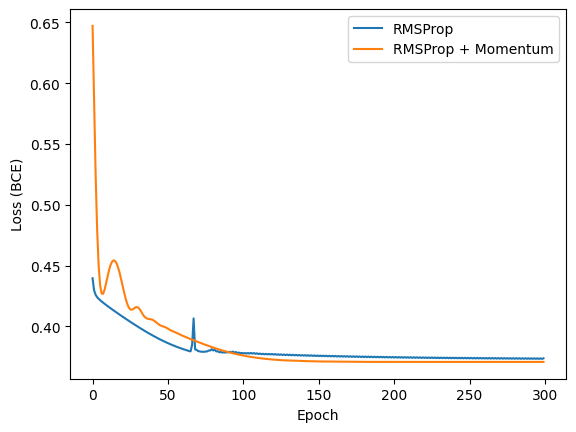

In [3]:
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, f1_score

p_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = (p_rf >= 0.5).astype(int)
print("Random Forest (تصويت متساوي) - Test:",
      {"Loss": round(log_loss(y_test, p_rf), 4),
       "Accuracy": round(accuracy_score(y_test, pred_rf), 4),
       "Precision": round(precision_score(y_test, pred_rf), 4),
       "Recall": round(recall_score(y_test, pred_rf), 4),
       "F1": round(f1_score(y_test, pred_rf), 4)})

def rmsprop(X, y, lr=0.01, epochs=300, rho=0.9, eps=1e-8, beta=0.0):
    w = np.zeros((X.shape[1], 1))
    s = np.zeros_like(w)   # المتوسط المتحرك لمربع الـ gradient
    v = np.zeros_like(w)   # الـ velocity (momentum)
    losses = []
    for _ in range(epochs):
        grad = X.T @ (sigmoid(X @ w) - y) / len(y)
        s = rho * s + (1 - rho) * grad**2
        v = beta * v + grad / (np.sqrt(s) + eps)
        w = w - lr * v
        losses.append(bce_loss(X, y, w))
    return w, losses

w_rms, loss_rms = rmsprop(Xb_train, y_train, lr=0.01, beta=0.0)
w_rmsm, loss_rmsm = rmsprop(Xb_train, y_train, lr=0.001, beta=0.9)

results = pd.DataFrame({
    "RMSProp (Train)": evaluate(Xb_train, y_train, w_rms),
    "RMSProp (Test)": evaluate(Xb_test, y_test, w_rms),
    "RMSProp+Momentum (Train)": evaluate(Xb_train, y_train, w_rmsm),
    "RMSProp+Momentum (Test)": evaluate(Xb_test, y_test, w_rmsm),
}).T.round(4)
print(results)

plt.plot(loss_rms, label="RMSProp")
plt.plot(loss_rmsm, label="RMSProp + Momentum")
plt.xlabel("Epoch"); plt.ylabel("Loss (BCE)"); plt.legend(); plt.show()

# Learning Random Forest Tree Weights with RMSProp (and Momentum)

## الهدف
تعلّم وزن لكل شجرة من أشجار الـ Random Forest بدل التصويت المتساوي، باستخدام RMSProp مكتوب من الصفر، ومقارنته مع RMSProp مع momentum، وذلك للتنبؤ بنجاة ركاب Titanic (target: 1 نجا، 0 ما نجا).

## البيانات
- داتا Titanic بعد التنظيف: 891 صف و7 features.
- قسمت البيانات: 80% تدريب (712 صف) و20% اختبار (179 صف) مع الحفاظ على نسبة الفئات (stratify).
- بنينا Random Forest من 50 شجرة (max_depth = 5)، وطلعنا احتمال كل شجرة للـ class 1، فصار عندنا مصفوفة [عينات × 50 شجرة]. للتدريب استخدمنا احتمالات الـ out-of-bag، وطبقنا StandardScaler على المصفوفة.

## طريقة العمل
- النموذج: p = sigmoid(P @ w)، حيث w وزن كل شجرة، والتصنيف: 1 إذا p >= 0.5.
- الـ Loss: Binary Cross-Entropy.
- RMSProp بيحتفظ بمتوسط متحرك لمربع الـ gradient: s = rho * s + (1 - rho) * grad².
- قاعدة التحديث: v = beta * v + grad / (sqrt(s) + eps) ثم w = w - lr * v.
- يعني كل وزن بياخد خطوة بحجم مناسب له، لأن الـ gradient بينقسم على حجمه التاريخي.
- المقاييس (محسوبة من الصفر من الـ confusion matrix): Accuracy و Precision و Recall و F1.

## الإعدادات
| الطريقة | learning rate | beta | rho | epochs |
|---|---|---|---|---|
| RMSProp | 0.01 | 0 | 0.9 | 300 |
| RMSProp + Momentum | 0.001 | 0.9 | 0.9 | 300 |

## النتائج
| الطريقة | Loss | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Random Forest (تصويت متساوي) - Test | 0.4581 | 0.7933 | 0.8200 | 0.5942 | 0.6891 |
| RMSProp (Train) | 0.3736 | 0.8441 | 0.8320 | 0.7436 | 0.7853 |
| RMSProp (Test) | 0.5766 | 0.7765 | 0.7458 | 0.6377 | 0.6875 |
| RMSProp+Momentum (Train) | 0.3707 | 0.8525 | 0.8559 | 0.7399 | 0.7937 |
| RMSProp+Momentum (Test) | 0.6083 | 0.7654 | 0.7288 | 0.6232 | 0.6719 |

## الملاحظات
- منحنى RMSProp العادي (الأزرق) بدأ من loss حوالي 0.44 ونزل بشكل ناعم لحوالي 0.38 عند epoch 65 تقريباً، وبعدها صارت قفزة حادة وحدة (لحوالي 0.42) ورجع بسرعة، ووصل بنهاية الـ 300 epoch لحوالي 0.374.
- سبب القفزة إنه لما الـ gradient بيصغر، المتوسط s بيصغر معه، فخطوة الـ RMSProp (grad / sqrt(s)) بتضل بحجم ثابت تقريباً بغض النظر عن حجم الـ gradient. فقرب الحل الخطوة بتصير كبيرة نسبياً وبتتجاوز الحل شوي.
- منحنى الـ momentum (البرتقالي) بدأ من loss عالي جداً (حوالي 0.65) ونزل بسرعة لحوالي 0.43 بأول 10 epochs، وبعدين طلع لحوالي 0.46 عند epoch 15 إلى 20 وصار فيه تذبذب صغير قبل ما يستقر. هاد الـ overshoot سببه تجمع الـ velocity بالبداية.
- بعد حوالي 100 epoch صار منحنى الـ momentum أنعم وأقل شوي من العادي، ووصل Train Loss لـ 0.3707 مقابل 0.3736. يعني الـ momentum هون سرّع النزول الأخير وخلّى المنحنى أنعم، بس بدأ أبطأ.
- مقارنة بالـ SGD والـ Mini-batch: تذبذب RMSProp أقل بكثير (قفزة وحدة بدل قفزات متكررة)، لأنه بيستخدم كل بيانات التدريب بكل تحديث (full batch) فما في ضجيج عشوائي.
- الأداء على الاختبار أضعف من الـ Random Forest العادي: Test Loss 0.5766 (بدون momentum) و0.6083 (مع momentum) مقابل 0.4581. وهو أفضل شوي من SGD والـ Mini-batch (حوالي 0.61)، بس أضعف من الـ GD العادي (0.4783).
- الفجوة بين التدريب والاختبار واضحة: الـ Loss من 0.37 لـ 0.58 إلى 0.61، والـ Accuracy من 0.84 إلى 0.85 لـ 0.77 إلى 0.78. الأوزان تأقلمت مع بيانات التدريب أكثر من اللازم، لأنه الأشجار الخمسين متشابهة بتنبؤاتها فالأوزان الصغيرة بتتضخم.
- فرق الـ Test Accuracy بين الطريقتين (0.7765 مقابل 0.7654) هو عينتين من 179، فهو ضجيج مش تحسن حقيقي، وبالاتجاه المعاكس: الـ momentum حسّن التدريب بس بدّل شوي بالاختبار.
- الـ Precision (0.73 إلى 0.75) أعلى من الـ Recall (0.62 إلى 0.64)، يعني النموذج بيفوّت حوالي 36% إلى 38% من الناجين الحقيقيين، نفس النمط بالنوتبوكات السابقة.

## الخلاصة
RMSProp أعطى Test Accuracy حوالي 77% وF1 حوالي 0.67 إلى 0.69، وهي قريبة من باقي الـ optimizers وأضعف شوي من الـ Random Forest العادي (79%). الـ momentum سرّع التقارب بالنهاية وخلّى المنحنى أنعم، بس ما حسّن الأداء على الاختبار. الأوزان المتعلمة بتعمل overfitting، فالتصويت المتساوي بيبقى أقوى بهالمسألة.